In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/nba-xgboost'
DATA_DIR = f"{BASE}/data"
OUT_DIR = f"{BASE}/outputs"

data = pd.read_csv(f"{DATA_DIR}/model_data.csv", parse_dates=['GAME_DATE'])
data = data.sort_values(['GAME_DATE','GAME_ID']).reset_index(drop=True)

DIFF = [c for c in data.columns if c.endswith('_DIFF')]
print(data.shape, len(DIFF), "features")

Mounted at /content/drive
(10738, 24) 19 features


In [2]:
cut = int(len(data) * 0.8)
cut_date = data.loc[cut, 'GAME_DATE']

# Move the cut to a date boundary so no single day is split between train and test
cut = data.index[data['GAME_DATE'] >= cut_date][0]
print("Cut row:", cut, "| Cut date:", cut_date.date())

Cut row: 8590 | Cut date: 2024-12-02


In [3]:
train = data.iloc[:cut].copy()
test = data.iloc[cut:].copy()

print("Train:", train.shape, train['GAME_DATE'].min().date(), "->", train['GAME_DATE'].max().date())
print("Test :", test.shape, test['GAME_DATE'].min().date(), "->", test['GAME_DATE'].max().date())
print("Train share:", round(len(train)/len(data), 4))

Train: (8590, 24) 2017-10-17 -> 2024-12-01
Test : (2148, 24) 2024-12-02 -> 2026-04-12
Train share: 0.8


In [4]:
print("Latest train date < earliest test date:", train['GAME_DATE'].max() < test['GAME_DATE'].min())
print("Shared GAME_IDs:", len(set(train.GAME_ID) & set(test.GAME_ID)), "(expect 0)")

Latest train date < earliest test date: True
Shared GAME_IDs: 0 (expect 0)


In [5]:
train_rate = train['HOME_WIN'].mean()
test_rate = test['HOME_WIN'].mean()

print(f"Train home-win rate: {train_rate:.2%}")
print(f"Test home-win rate : {test_rate:.2%}  ({int(test['HOME_WIN'].sum())} of {len(test)})")

Train home-win rate: 56.30%
Test home-win rate : 54.56%  (1172 of 2148)


In [6]:
y = test['HOME_WIN']
acc = y.mean()                       # accuracy = share of home wins
precision_home = y.mean()
recall_home = 1.0
f1_home = 2*precision_home*recall_home/(precision_home+recall_home)
f1_away = 0.0                         # never predicts away
macro_f1 = (f1_home + f1_away)/2
brier = ((train_rate - y)**2).mean()  # constant probability = train home-win rate

print(f"Accuracy {acc:.2%} | Precision(home) {precision_home:.2f} | Recall(home) {recall_home:.0f} | Macro F1 {macro_f1:.2f} | Brier {brier:.4f}")

Accuracy 54.56% | Precision(home) 0.55 | Recall(home) 1 | Macro F1 0.35 | Brier 0.2482


In [7]:
corr = train[DIFF + ['HOME_WIN']].corr()['HOME_WIN'].drop('HOME_WIN')
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
print(corr.round(3))

PLUS_MINUS_DIFF    0.283
PTS_DIFF           0.180
FG_PCT_DIFF        0.178
FGM_DIFF           0.144
DREB_DIFF          0.132
FG3_PCT_DIFF       0.126
FG3M_DIFF          0.124
AST_DIFF           0.102
TOV_DIFF          -0.101
REB_DIFF           0.091
BLK_DIFF           0.087
FT_PCT_DIFF        0.071
FG3A_DIFF          0.070
PF_DIFF           -0.054
STL_DIFF           0.046
FTM_DIFF           0.041
OREB_DIFF         -0.031
FGA_DIFF          -0.015
FTA_DIFF           0.014
Name: HOME_WIN, dtype: float64


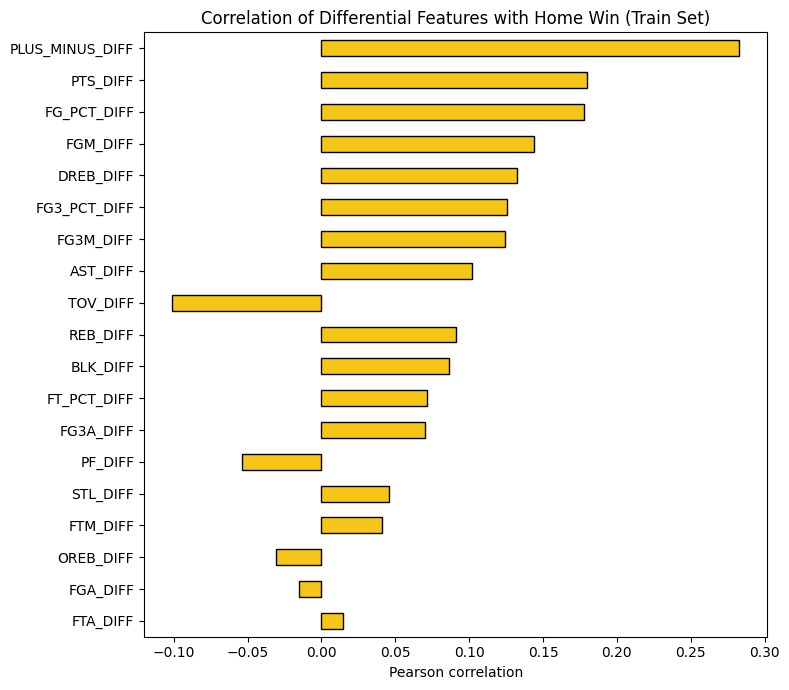

In [8]:
fig, ax = plt.subplots(figsize=(8, 7))
corr[::-1].plot(kind='barh', color='#F5C518', edgecolor='black', ax=ax)
ax.set_title('Correlation of Differential Features with Home Win (Train Set)')
ax.set_xlabel('Pearson correlation')
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/correlation_with_target.png", dpi=200)
plt.show()

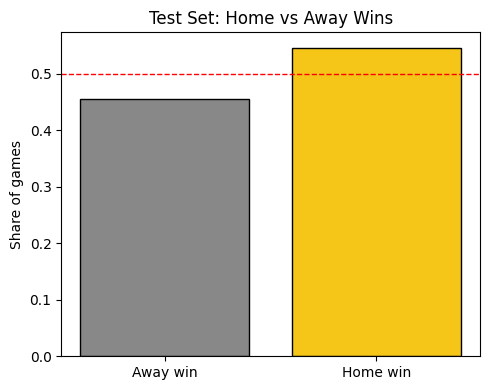

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
labels = ['Away win', 'Home win']
ax.bar(labels, [1 - test_rate, test_rate], color=['#888888', '#F5C518'], edgecolor='black')
ax.axhline(0.5, color='red', linestyle='--', linewidth=1)
ax.set_title('Test Set: Home vs Away Wins')
ax.set_ylabel('Share of games')
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/home_win_baseline.png", dpi=200)
plt.show()

In [10]:
train.to_csv(f"{DATA_DIR}/train.csv", index=False)
test.to_csv(f"{DATA_DIR}/test.csv", index=False)
print("Saved train", train.shape, "and test", test.shape)

Saved train (8590, 24) and test (2148, 24)
